Me trying things out. I'm copying and pasting things from the MDST tutorial. Let's hope that it works!

In [1]:
# Since typing pandas or numpy every single time is too long and tedious, we assign them shorter nicknames like pd and np.
# You can technically use any name, such as a wolverine instead of pd and np, but pd and np are the standard conventions used by data scientists.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Suppress Pandas SettingWithCopyWarning
pd.options.mode.chained_assignment = None

In [2]:
# 'df' stands for DataFrame. Unlike libraries (pd/np), we do NOT import it.
# Instead, we create it directly by assigning the result of read_csv to a variable named 'df'.
# Just like 'pd', you can technically use any name (e.g., 'wolverine') instead of 'df'.
# However, 'df' is the standard convention used by data scientists worldwide.
df2026 = pd.read_csv('2026_UEFA_WCQ.csv')
df2022 = pd.read_csv('2022_UEFA_WCQ.csv')
df2018 = pd.read_csv('2018_UEFA_WCQ.csv')

In [3]:
df2026.shape, df2022.shape, df2018.shape
#for whatever reason 2022 has an extra row
#gonna look into that later
# -Ryan

((55, 21), (56, 21), (55, 21))

In [4]:
# Displays the first 5 rows. Great for a quick sanity check to see what our data actually looks like.
df2026.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Playing Time,Playing Time.1,Playing Time.2,Playing Time.3,Performance,Performance.1,...,Performance.3,Performance.4,Performance.5,Performance.6,Performance.7,Per 90 Minutes,Per 90 Minutes.1,Per 90 Minutes.2,Per 90 Minutes.3,Per 90 Minutes.4
0,Squad,# Pl,Age,Poss,MP,Starts,Min,90s,Gls,Ast,...,G-PK,PK,PKatt,CrdY,CrdR,Gls,Ast,G+A,G-PK,G+A-PK
1,al Albania,26,28.8,52.9,9,99,810,9.0,7,5,...,6,1,2,11,0,0.78,0.56,1.33,0.67,1.22
2,ad Andorra,28,26.3,25.9,8,88,720,8.0,3,2,...,3,0,0,15,1,0.37,0.25,0.62,0.37,0.62
3,am Armenia,25,26.8,39.5,6,66,540,6.0,3,2,...,2,1,1,5,1,0.50,0.33,0.83,0.33,0.67
4,at Austria,28,29.1,64.3,8,88,720,8.0,22,17,...,20,2,3,15,1,2.75,2.12,4.87,2.50,4.62


In [5]:
df2022.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Playing Time,Playing Time.1,Playing Time.2,Playing Time.3,Performance,Performance.1,...,Performance.3,Performance.4,Performance.5,Performance.6,Performance.7,Per 90 Minutes,Per 90 Minutes.1,Per 90 Minutes.2,Per 90 Minutes.3,Per 90 Minutes.4
0,Squad,# Pl,Age,Poss,MP,Starts,Min,90s,Gls,Ast,...,G-PK,PK,PKatt,CrdY,CrdR,Gls,Ast,G+A,G-PK,G+A-PK
1,al Albania,34,27.5,53.8,10,110,900,10.0,12,9,...,11,1,1,29,0,1.20,0.90,2.10,1.10,2.00
2,ad Andorra,29,28.6,26.6,10,110,900,10.0,8,7,...,7,1,1,30,1,0.80,0.70,1.50,0.70,1.40
3,am Armenia,31,29.4,44.7,10,110,900,10.0,8,5,...,5,3,3,19,0,0.80,0.50,1.30,0.50,1.00
4,at Austria,36,28.2,62.5,11,121,990,11.0,20,12,...,18,2,2,14,0,1.82,1.09,2.91,1.64,2.73


In [6]:
df2018.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Playing Time,Playing Time.1,Playing Time.2,Playing Time.3,Performance,Performance.1,...,Performance.3,Performance.4,Performance.5,Performance.6,Performance.7,Per 90 Minutes,Per 90 Minutes.1,Per 90 Minutes.2,Per 90 Minutes.3,Per 90 Minutes.4
0,Squad,# Pl,Age,Poss,MP,Starts,Min,90s,Gls,Ast,...,G-PK,PK,PKatt,CrdY,CrdR,Gls,Ast,G+A,G-PK,G+A-PK
1,al Albania,32,28.4,NaN,10,110,900,10.0,9,7,...,9,0,0,22,2,0.90,0.70,1.60,0.90,1.60
2,ad Andorra,26,28.4,NaN,10,110,900,10.0,2,1,...,2,0,0,37,2,0.20,0.10,0.30,0.20,0.30
3,am Armenia,34,27.4,NaN,10,110,900,10.0,10,7,...,10,0,0,22,3,1.00,0.70,1.70,1.00,1.70
4,at Austria,30,27.3,NaN,10,110,900,10.0,14,11,...,14,0,0,20,0,1.40,1.10,2.50,1.40,2.50


In [7]:
# Lists all column names. Very useful when you need to copy-paste exact names later to avoid typos.
df2026.columns
#columns should be the same across all 3 datasets - Ryan

Index(['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Playing Time',
       'Playing Time.1', 'Playing Time.2', 'Playing Time.3', 'Performance',
       'Performance.1', 'Performance.2', 'Performance.3', 'Performance.4',
       'Performance.5', 'Performance.6', 'Performance.7', 'Per 90 Minutes',
       'Per 90 Minutes.1', 'Per 90 Minutes.2', 'Per 90 Minutes.3',
       'Per 90 Minutes.4'],
      dtype='str')

I should really figure out how to rename these column heads, but I'm at a loss. 

I'm going to start out by renaming those column heads!

In [8]:
#I'm going to put all the data refactoring into one cell to make it easier to read and edit later - Ryan

#--------------------------------

column_names = {
    'Unnamed: 0': 'Squad',
    'Unnamed: 1': 'Num_Players',
    'Unnamed: 2': 'Age_Players',
    'Unnamed: 3': 'Possession',
    'Playing Time': 'Matches_Played',
    'Playing Time.1': 'Starts',
    'Playing Time.2': 'Minutes',
    'Playing Time.3': '90s Played',
    'Performance': 'Goals',
    'Performance.1': 'Assists',
    'Performance.2': 'Goals and Assists',
    'Performance.3': 'Non-Penalty Goals',
    'Performance.4': 'Penalty Kicks Made',
    'Performance.5': 'Penalty Kicks Attempted',
    'Performance.6': 'Yellow Cards',
    'Performance.7': 'Red Cards'
}

#--------------------------------

for df in [df2026, df2022, df2018]:
    df.rename(columns=column_names, inplace=True)
    df.drop(index=df.index[0], inplace=True)

#--------------------------------

cols_to_convert = ['Num_Players', 'Age_Players', 'Possession', 'Matches_Played',
       'Starts', 'Minutes', '90s Played', 'Goals', 'Assists',
       'Goals and Assists', 'Non-Penalty Goals', 'Penalty Kicks Made',
       'Penalty Kicks Attempted', 'Yellow Cards', 'Red Cards','Per 90 Minutes', 'Per 90 Minutes.1', 'Per 90 Minutes.2',
       'Per 90 Minutes.3', 'Per 90 Minutes.4']

df2026[cols_to_convert] = df2026[cols_to_convert].astype(float)
df2022[cols_to_convert] = df2022[cols_to_convert].astype(float)
df2018[cols_to_convert] = df2018[cols_to_convert].astype(float)

#--------------------------------
#ok so just notice quite the issue idk if it matters too much but the way we remove 
# the top row has it so that each time the iloc is run it shaves off the top row of the current one so 
# if you run this block 100 times it shaves off the top 100 rows
#idk if theres a fix for this but for now only run this block once - Ryan

In [9]:
df2026.shape, df2022.shape, df2018.shape


((54, 21), (55, 21), (54, 21))

Wow, zero NaNs! I hope that this data is actually decent. I guess there's no need to clean it?

In [10]:
df2026.isna().sum()

Squad                      0
Num_Players                0
Age_Players                0
Possession                 0
Matches_Played             0
Starts                     0
Minutes                    0
90s Played                 0
Goals                      0
Assists                    0
Goals and Assists          0
Non-Penalty Goals          0
Penalty Kicks Made         0
Penalty Kicks Attempted    0
Yellow Cards               0
Red Cards                  0
Per 90 Minutes             0
Per 90 Minutes.1           0
Per 90 Minutes.2           0
Per 90 Minutes.3           0
Per 90 Minutes.4           0
dtype: int64

EDA

The first step in EDA is usually looking at the variable of interest in isolation. What's its distribution? How has it changed over time?

2026 Histogram

Text(0, 0.5, 'Frequency')

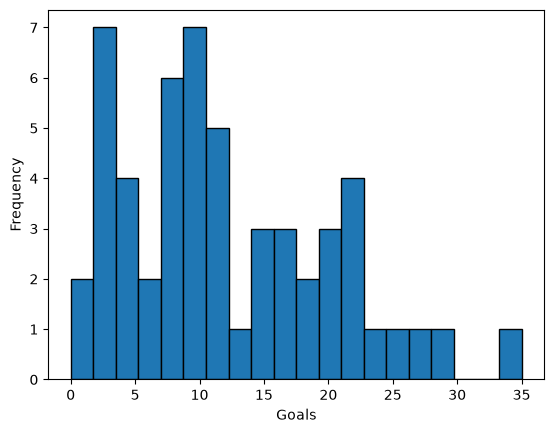

In [11]:
df2026["Goals"].hist(bins = 20, edgecolor="black", grid=False)
plt.xlabel('Goals')
plt.ylabel('Frequency')

2022 Histogram

Text(0, 0.5, 'Frequency')

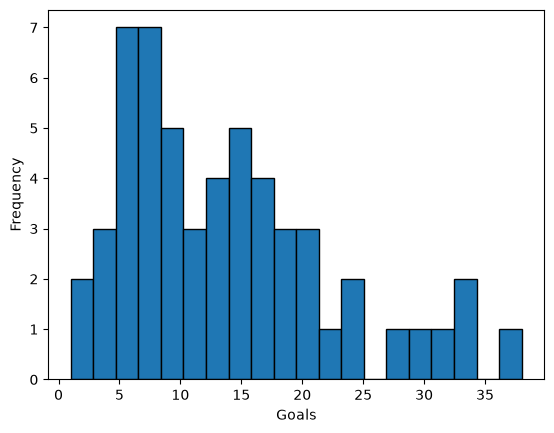

In [12]:
df2022["Goals"].hist(bins = 20, edgecolor="black", grid=False)
plt.xlabel('Goals')
plt.ylabel('Frequency')

2018 Histogram

Text(0, 0.5, 'Frequency')

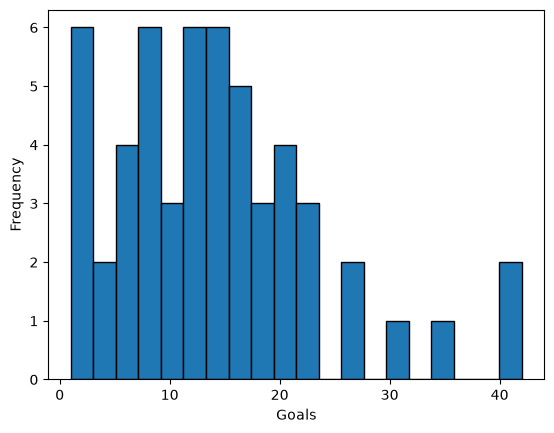

In [13]:
df2018["Goals"].hist(bins = 20, edgecolor="black", grid=False)
plt.xlabel('Goals')
plt.ylabel('Frequency')

Then, we can investigate the relationship between the variable of interest and other (potentially) relevant variables.

In [17]:
missing_in_df2026 = df2022[~df2022["Squad"].isin(df2026["Squad"])]
print(missing_in_df2026)

        Squad  Num_Players  Age_Players  Possession  Matches_Played  Starts  \
44  ru Russia         37.0         28.3        47.8            10.0   110.0   

    Minutes  90s Played  Goals  Assists  ...  Non-Penalty Goals  \
44    900.0        10.0   18.0     14.0  ...               17.0   

    Penalty Kicks Made  Penalty Kicks Attempted  Yellow Cards  Red Cards  \
44                 1.0                      1.0          16.0        0.0   

    Per 90 Minutes  Per 90 Minutes.1  Per 90 Minutes.2  Per 90 Minutes.3  \
44             1.8               1.4               3.2               1.7   

    Per 90 Minutes.4  
44               3.1  

[1 rows x 21 columns]


In [18]:
# Drop Russia
df2022 = df2022.drop(44)

In [19]:
# Ensure that columns for Squad in the same order
df2022 = df2022[df2026.columns]
df2018 = df2018[df2026.columns]

2022 vs 2026 Variables

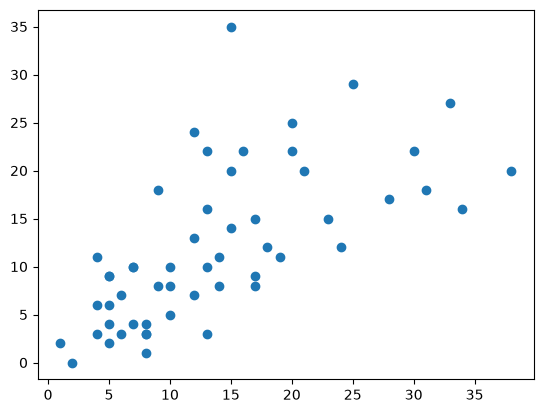

In [20]:
plt.scatter(y = df2026["Goals"], x = df2022["Goals"])

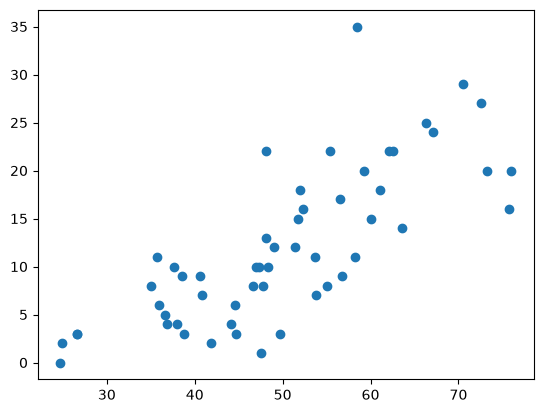

In [21]:
plt.scatter(y = df2026["Goals"], x = df2022["Possession"])

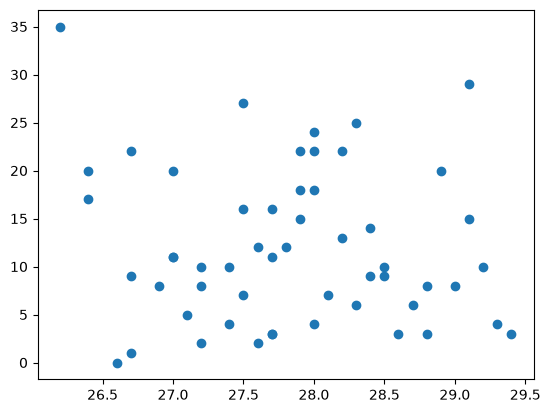

In [22]:
plt.scatter(y = df2026["Goals"], x = df2022["Age_Players"])

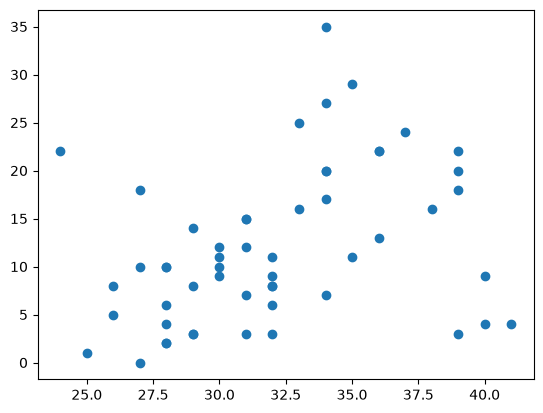

In [23]:
plt.scatter(y = df2026["Goals"], x = df2022["Num_Players"])

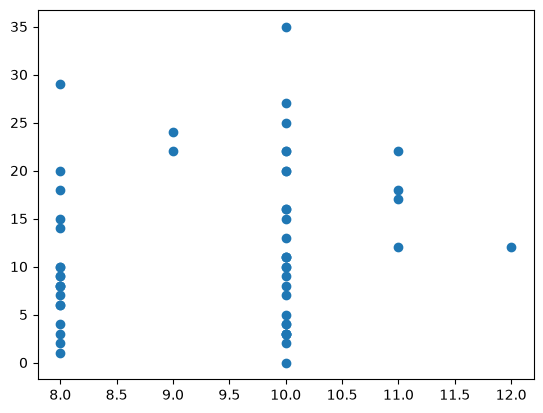

In [24]:
plt.scatter(y = df2026["Goals"], x = df2022["Matches_Played"])

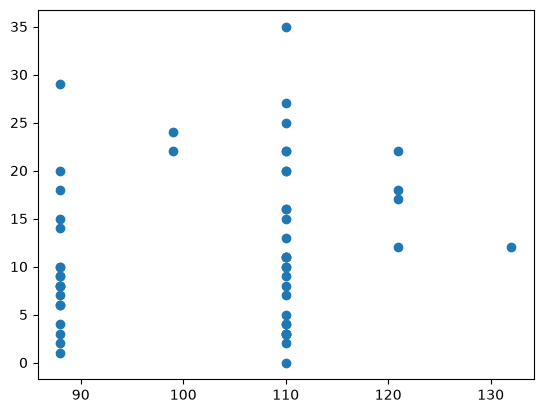

In [25]:
plt.scatter(y = df2026["Goals"], x = df2022["Starts"])

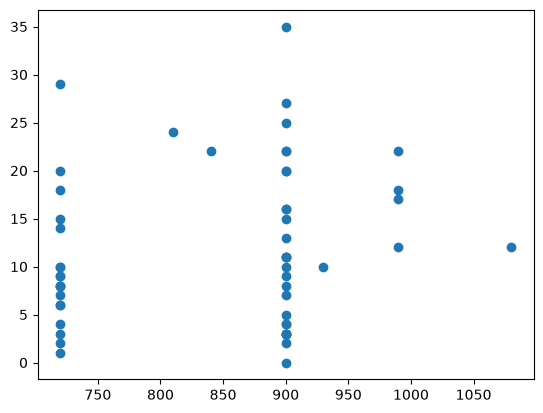

In [26]:
plt.scatter(y = df2026["Goals"], x = df2022["Minutes"])

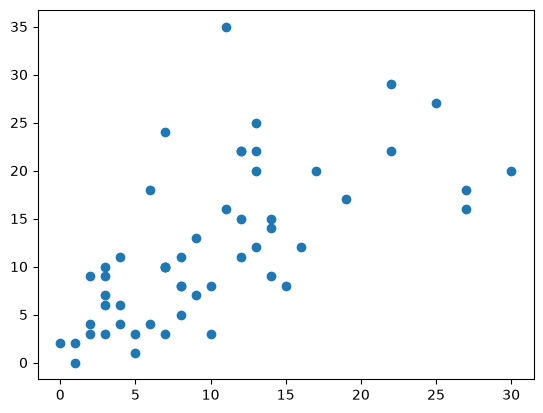

In [27]:
plt.scatter(y = df2026["Goals"], x = df2022["Assists"])

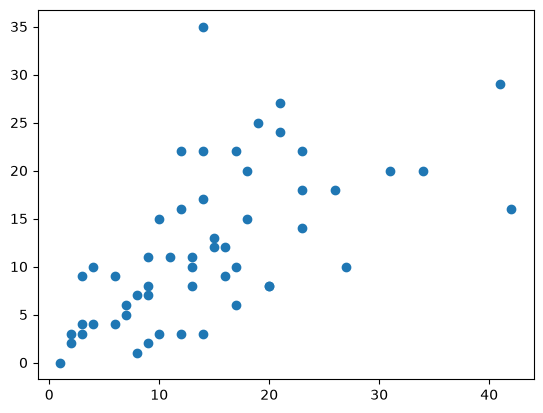

In [28]:
plt.scatter(y = df2026["Goals"], x = df2018["Goals"])

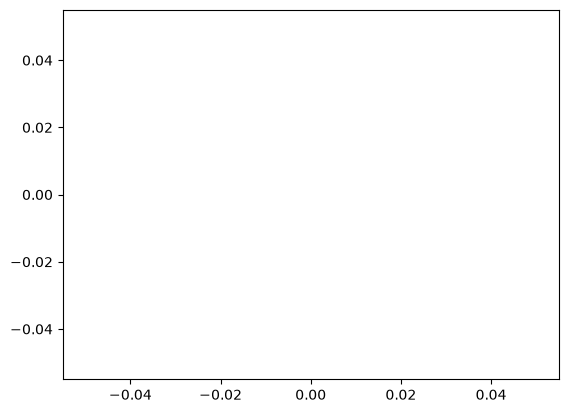

In [29]:
plt.scatter(y = df2026["Goals"], x = df2018["Possession"])

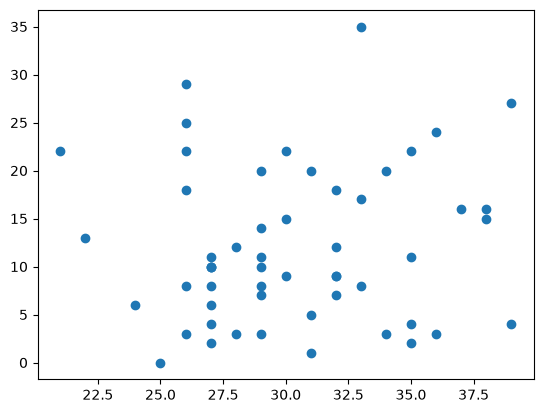

In [30]:
plt.scatter(y = df2026["Goals"], x = df2018["Num_Players"])

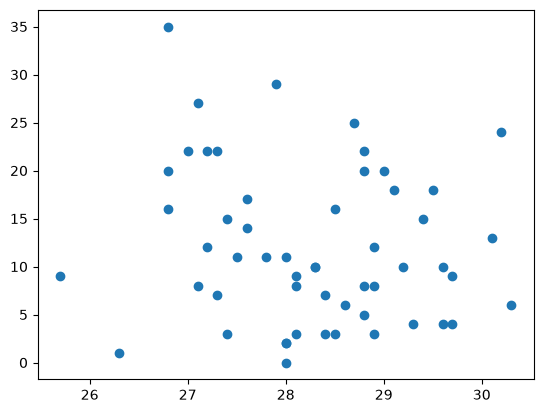

In [31]:
plt.scatter(y = df2026["Goals"], x = df2018["Age_Players"])

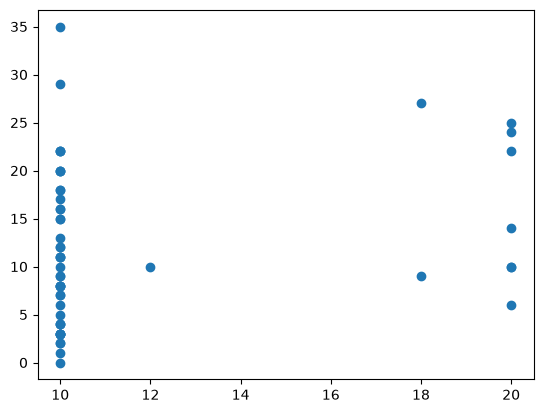

In [32]:
plt.scatter(y = df2026["Goals"], x = df2018["Matches_Played"])

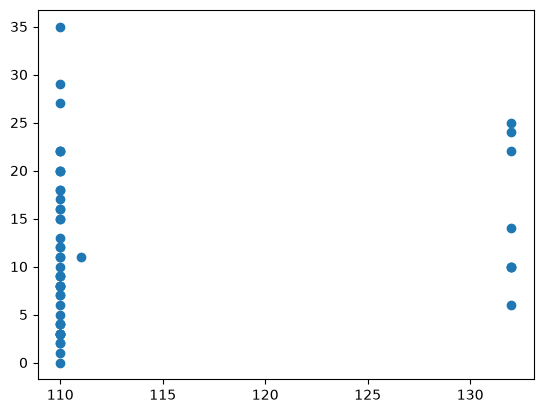

In [33]:
plt.scatter(y = df2026["Goals"], x = df2018["Starts"])

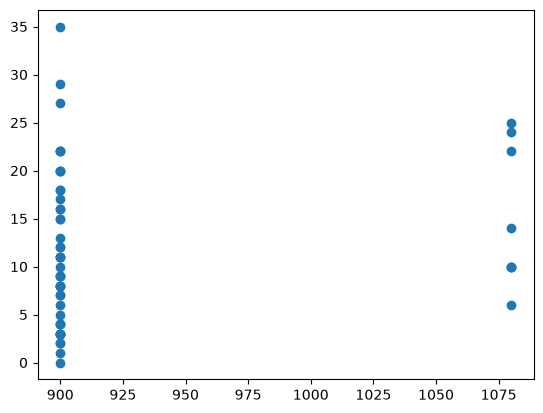

In [34]:
plt.scatter(y = df2026["Goals"], x = df2018["Minutes"])

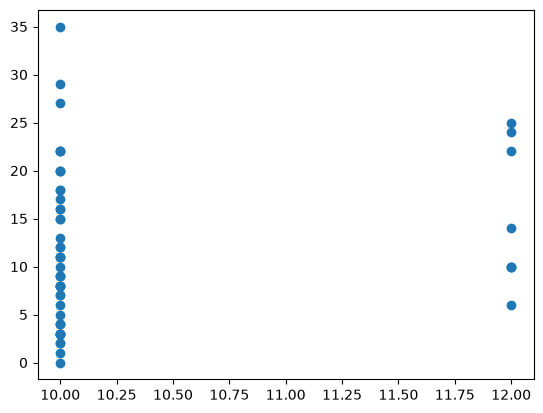

In [35]:
plt.scatter(y = df2026["Goals"], x = df2018["90s Played"])

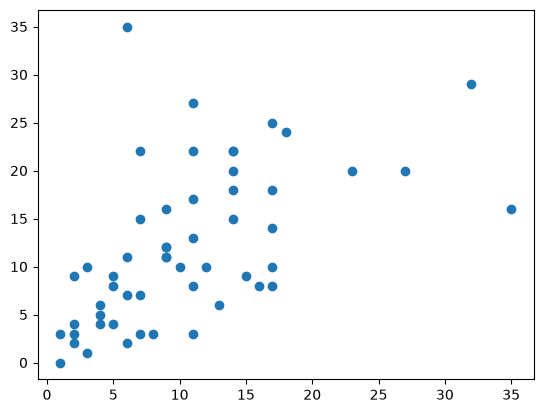

In [36]:
plt.scatter(y = df2026["Goals"], x = df2018["Assists"])

Correlations!

In [37]:
# Drop the squad column because .corr() only uses numeric stuff
dropped2026 = df2026.drop(columns = "Squad")
dropped2022 = df2022.drop(columns = "Squad")
dropped2018 = df2018.drop(columns = "Squad")

Start merging dataframes because heatmap only takes 1 dataframe

In [38]:
df2026.columns = [
    col if col == 'Squad' else col + ' 2026' for col in df2026.columns
]
df2026.columns

Index(['Squad', 'Num_Players 2026', 'Age_Players 2026', 'Possession 2026',
       'Matches_Played 2026', 'Starts 2026', 'Minutes 2026', '90s Played 2026',
       'Goals 2026', 'Assists 2026', 'Goals and Assists 2026',
       'Non-Penalty Goals 2026', 'Penalty Kicks Made 2026',
       'Penalty Kicks Attempted 2026', 'Yellow Cards 2026', 'Red Cards 2026',
       'Per 90 Minutes 2026', 'Per 90 Minutes.1 2026', 'Per 90 Minutes.2 2026',
       'Per 90 Minutes.3 2026', 'Per 90 Minutes.4 2026'],
      dtype='str')

In [39]:

df2026 = df2026.drop(columns = ['Age_Players 2026', 'Num_Players 2026', 'Matches_Played 2026', 'Starts 2026', 'Minutes 2026', '90s Played 2026', 'Per 90 Minutes 2026', 'Per 90 Minutes.1 2026', 'Per 90 Minutes.2 2026',
       'Per 90 Minutes.3 2026', 'Per 90 Minutes.4 2026'])


In [40]:
df2022.columns = [
    col if col == 'Squad' else col + ' 2022' for col in df2022.columns
]
df2022.columns

Index(['Squad', 'Num_Players 2022', 'Age_Players 2022', 'Possession 2022',
       'Matches_Played 2022', 'Starts 2022', 'Minutes 2022', '90s Played 2022',
       'Goals 2022', 'Assists 2022', 'Goals and Assists 2022',
       'Non-Penalty Goals 2022', 'Penalty Kicks Made 2022',
       'Penalty Kicks Attempted 2022', 'Yellow Cards 2022', 'Red Cards 2022',
       'Per 90 Minutes 2022', 'Per 90 Minutes.1 2022', 'Per 90 Minutes.2 2022',
       'Per 90 Minutes.3 2022', 'Per 90 Minutes.4 2022'],
      dtype='str')

In [41]:
df2022 = df2022.drop(columns = ['Age_Players 2022', 'Num_Players 2022', 'Matches_Played 2022', 'Starts 2022', 
                                'Minutes 2022', '90s Played 2022', 'Per 90 Minutes 2022', 'Per 90 Minutes.1 2022', 'Per 90 Minutes.2 2022',
       'Per 90 Minutes.3 2022', 'Per 90 Minutes.4 2022'])

In [42]:
df2018.columns = [
    col if col == 'Squad' else col + ' 2018' for col in df2018.columns
]
df2018.columns

Index(['Squad', 'Num_Players 2018', 'Age_Players 2018', 'Possession 2018',
       'Matches_Played 2018', 'Starts 2018', 'Minutes 2018', '90s Played 2018',
       'Goals 2018', 'Assists 2018', 'Goals and Assists 2018',
       'Non-Penalty Goals 2018', 'Penalty Kicks Made 2018',
       'Penalty Kicks Attempted 2018', 'Yellow Cards 2018', 'Red Cards 2018',
       'Per 90 Minutes 2018', 'Per 90 Minutes.1 2018', 'Per 90 Minutes.2 2018',
       'Per 90 Minutes.3 2018', 'Per 90 Minutes.4 2018'],
      dtype='str')

In [43]:
df2018 = df2018.drop(columns = ['Age_Players 2018', 'Num_Players 2018', 'Matches_Played 2018', 'Starts 2018', 
                                'Minutes 2018', '90s Played 2018', 'Per 90 Minutes 2018', 'Per 90 Minutes.1 2018', 'Per 90 Minutes.2 2018',
       'Per 90 Minutes.3 2018', 'Per 90 Minutes.4 2018'])

In [44]:
# Merge
res = pd.merge(df2026, df2022, on='Squad')
# Merge with 2018
res = pd.merge(res, df2018, on='Squad')

In [45]:
# Drop the squad column
res = res.drop(columns = "Squad")

In [46]:
corrs = res.corr(numeric_only=True)

In [47]:
# Since .corr returns a dataframe (corrs)
# Search all elements for corr with abs value >= 0.5???

pairs = corrs.unstack()
filtered_pairs = pairs[(pairs.abs() >= 0.5) & (pairs != 1.0)]
print(filtered_pairs)

Possession 2026    Goals 2026                 0.806778
                   Assists 2026               0.774882
                   Goals and Assists 2026     0.797598
                   Non-Penalty Goals 2026     0.775681
                   Penalty Kicks Made 2026    0.628984
                                                ...   
Yellow Cards 2018  Non-Penalty Goals 2022    -0.571846
                   Goals 2018                -0.588432
                   Assists 2018              -0.548730
                   Goals and Assists 2018    -0.575334
                   Non-Penalty Goals 2018    -0.562342
Length: 252, dtype: float64


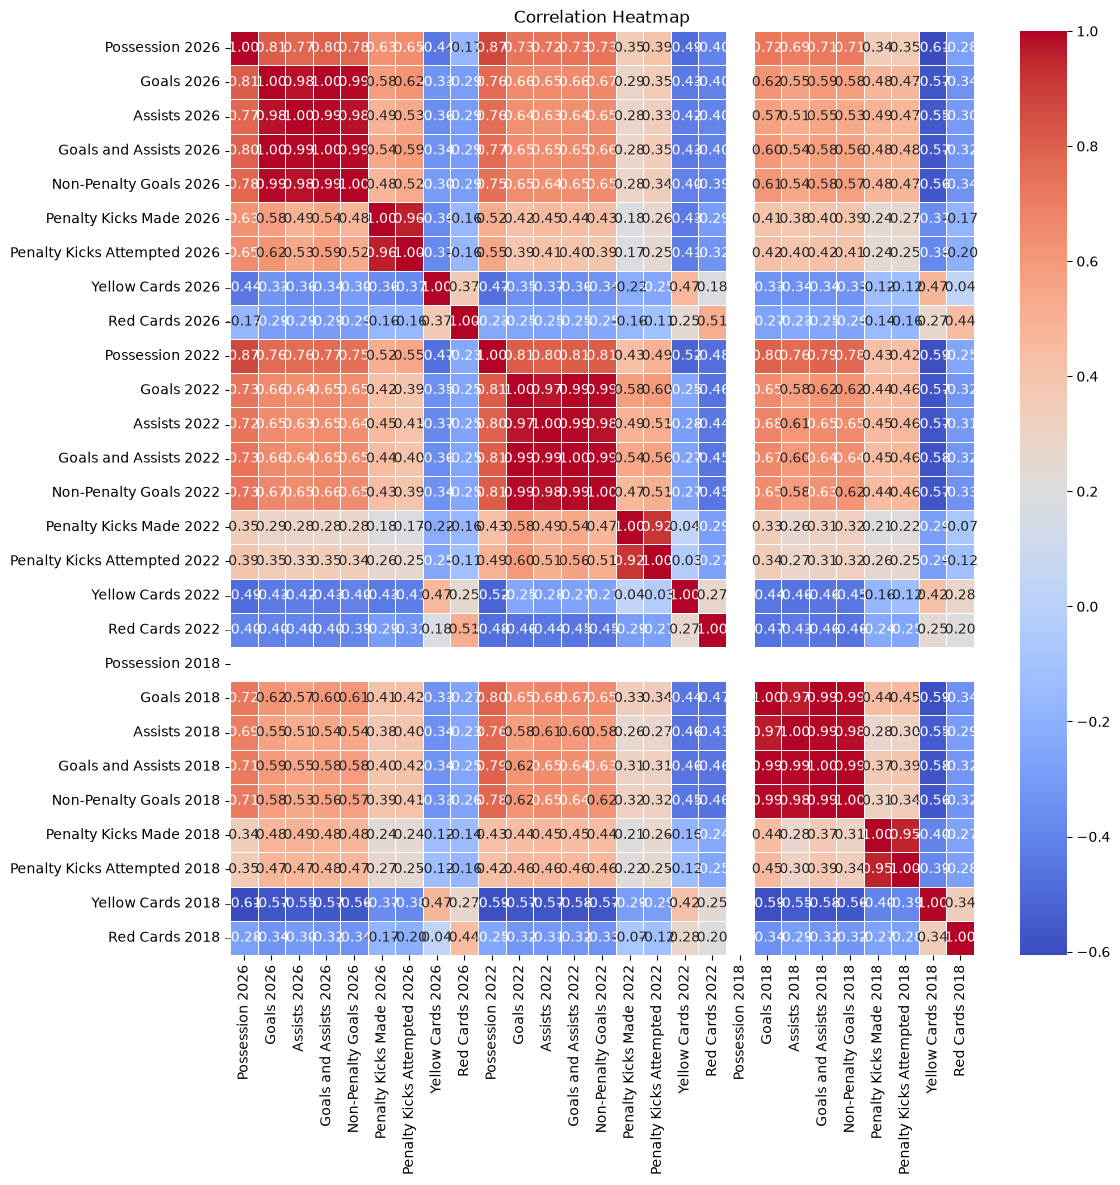

In [48]:
# That's not very easy to understand, but it's nice to have exact numbers
# Let's do a more visual way

plt.figure(figsize=(12, 12)) # Adjust figure size as needed
sns.heatmap(res.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap')
plt.show()

In [49]:
# To make our heatmap more readable, drop penalty kicks and cards
res.columns

Index(['Possession 2026', 'Goals 2026', 'Assists 2026',
       'Goals and Assists 2026', 'Non-Penalty Goals 2026',
       'Penalty Kicks Made 2026', 'Penalty Kicks Attempted 2026',
       'Yellow Cards 2026', 'Red Cards 2026', 'Possession 2022', 'Goals 2022',
       'Assists 2022', 'Goals and Assists 2022', 'Non-Penalty Goals 2022',
       'Penalty Kicks Made 2022', 'Penalty Kicks Attempted 2022',
       'Yellow Cards 2022', 'Red Cards 2022', 'Possession 2018', 'Goals 2018',
       'Assists 2018', 'Goals and Assists 2018', 'Non-Penalty Goals 2018',
       'Penalty Kicks Made 2018', 'Penalty Kicks Attempted 2018',
       'Yellow Cards 2018', 'Red Cards 2018'],
      dtype='str')

In [50]:
noKicksCards = res.drop(columns = ['Penalty Kicks Made 2026', 'Penalty Kicks Attempted 2026', 
                                   'Yellow Cards 2026', 'Red Cards 2026',
                                   'Penalty Kicks Made 2022', 'Penalty Kicks Attempted 2022',
                                   'Yellow Cards 2022', 'Red Cards 2022',
                                   'Penalty Kicks Made 2018', 'Penalty Kicks Attempted 2018',
                                   'Yellow Cards 2018', 'Red Cards 2018'])

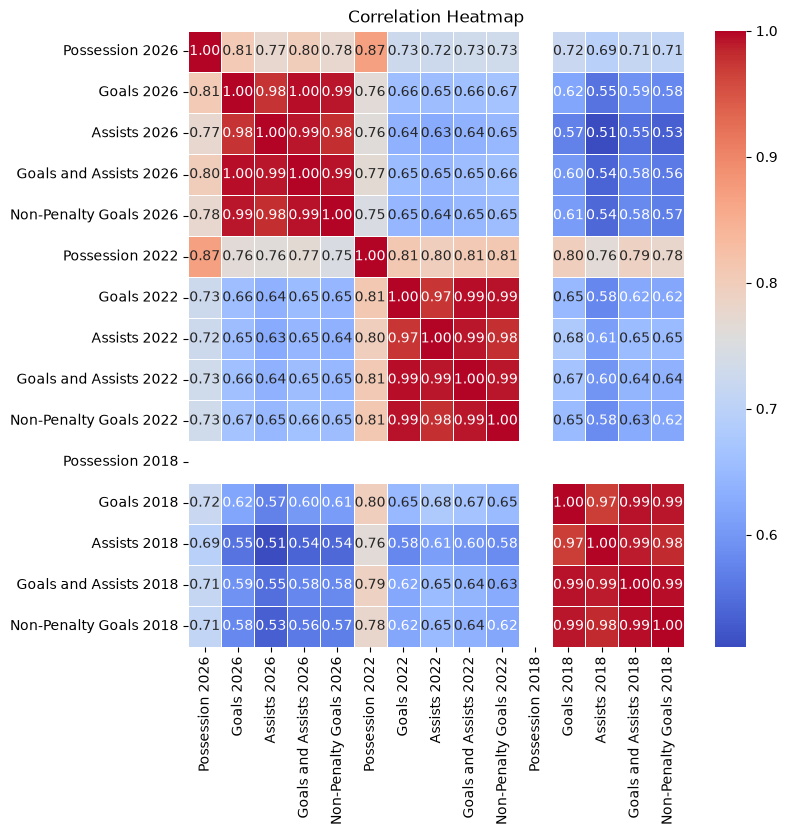

In [51]:
# That's not very easy to understand, but it's nice to have exact numbers
# Let's do a more visual way

plt.figure(figsize=(8, 8)) # Adjust figure size as needed
sns.heatmap(noKicksCards.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap')
plt.show()

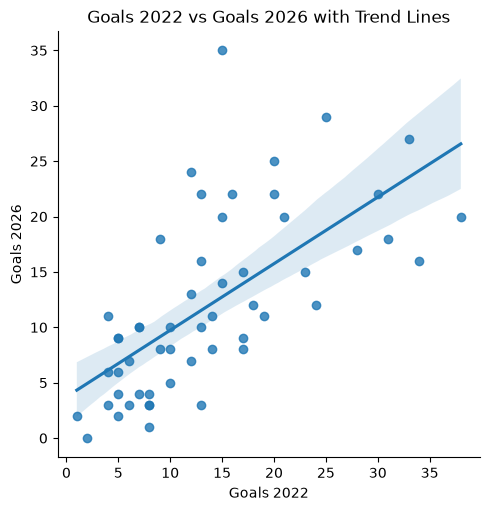

In [52]:
# Regression Line plot -- could be useful after making a model...

sns.lmplot(data=noKicksCards, x='Goals 2022', y='Goals 2026', height=5)
plt.title('Goals 2022 vs Goals 2026 with Trend Lines')
plt.show()